# ДЗ-1. Yambda
Иван Ларин

Рекомендуем 10 незнакомых треков по истории прослушиваний.

## Данные
[Yambda-50M](https://huggingface.co/datasets/yandex/yambda): около 47,8 млн событий. Загружаем прослушивания, реакции, исполнителей и альбомы.

`uid`, `item_id` — пользователь и трек; `timestamp` — время; `event_type` — действие; `played_ratio_pct` — процент прослушанного; `track_length_seconds` — длительность; `is_organic` — самостоятельный выбор.

Python 3.13: `pip install -r requirements.txt`, затем выполнить все ячейки. Данные загрузятся автоматически.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.sparse import csr_matrix
from threadpoolctl import threadpool_limits

from evaluation import evaluate
from models.neighbors import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FM
from models.custom_ials import CustomIALS

SEED = 42
START, VALIDATION, TEST, END = 20_000_000, 24_000_000, 25_000_000, 26_000_001

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
limits = threadpool_limits(4)

In [2]:
url = "https://huggingface.co/datasets/yandex/yambda/resolve/dd6f3a19eef5866e346c3270e098baa641a44948/"
files = ["flat/50m/multi_event.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]
Path("data").mkdir(exist_ok=True)

for name in files:
    path = Path("data") / Path(name).name
    if not path.exists():
        urlretrieve(url + name, path)

## Подготовка
Берём случайных пользователей и популярные в train треки, чтобы ограничить размер задачи. Пользователей с короткой историей исключаем.

Удаляем полные дубликаты и некорректные прослушивания. Пропуски длительности у реакций нормальны. Старую историю сохраняем для исключения знакомых треков и учёта реакций.

In [3]:
all_users = pd.read_parquet("data/multi_event.parquet", columns=["uid"]).uid
original_size = len(all_users)
users = np.random.default_rng(SEED).choice(np.sort(all_users.unique()), 1500, replace=False)

data = pd.read_parquet("data/multi_event.parquet", filters=[("uid", "in", users)])
display(data.isna().sum())
print("Дубликаты:", data.duplicated().sum())

data = data.drop_duplicates()
listened = data.event_type == "listen"
data = data[~listened | (data.played_ratio_pct.notna() & (data.track_length_seconds > 0))]

uid                          0
timestamp                    0
item_id                      0
is_organic                   0
played_ratio_pct        189997
track_length_seconds    189997
event_type                   0
dtype: int64

Дубликаты: 33389


In [4]:
train = data[(data.timestamp >= START) & (data.timestamp < VALIDATION)]
train = train[train.event_type == "listen"]
popularity = train.groupby("item_id").size()
items = popularity.sort_values(ascending=False, kind="stable").head(2000).index

activity = train[train.item_id.isin(items)].groupby("uid").item_id.nunique()
users = activity[activity >= 5].index
history = data[data.uid.isin(users) & data.item_id.isin(items)].copy()

history["user"] = pd.Categorical(history.uid, categories=users).codes
history["item"] = pd.Categorical(history.item_id, categories=items).codes
history = history.sort_values(["timestamp", "uid", "item_id"], kind="stable")
events = history[history.timestamp >= START]
shape = (len(users), len(items))

assert 100_000 <= len(events) <= len(history) <= 2_000_000
assert min(shape) >= 1000

print("Исходно событий:", original_size)
print("После отбора:", len(history), "; в окне эксперимента:", len(events))
print("Пользователей и треков:", shape)

Исходно событий: 47790449
После отбора: 1725095 ; в окне эксперимента: 581102
Пользователей и треков: (1178, 2000)


In [5]:
metadata = pd.DataFrame(index=items)

for name in ["artist", "album"]:
    mapping = pd.read_parquet(f"data/{name}_item_mapping.parquet", filters=[("item_id", "in", items)])
    metadata[name] = mapping.groupby("item_id")[f"{name}_id"].min()

train = history[(history.timestamp >= START) & (history.timestamp < VALIDATION)]
metadata["duration"] = train[train.event_type == "listen"].groupby("item_id").track_length_seconds.median()
metadata["length"] = pd.cut(metadata.duration, [0, 120, 180, 240, 300, np.inf], labels=False)

features = [np.arange(len(items))]
offset = len(items)

for name in ["artist", "album", "length"]:
    codes = pd.factorize(metadata[name], sort=True)[0] + 1
    features.append(codes + offset)
    offset += codes.max() + 1

features = np.array(features).T
metadata.agg(["count", "nunique"])

,artist,album,duration,length
count,2000,2000,2000,2000
nunique,1088,1748,66,5


In [6]:
display(events.event_type.value_counts())
pairs = events[["user", "item"]].drop_duplicates()
print("Разреженность:", 1 - len(pairs) / np.prod(shape))

event_type
listen       570842
like           8357
unlike         1050
dislike         751
undislike       102
Name: count, dtype: int64

Разреженность: 0.9164482173174873


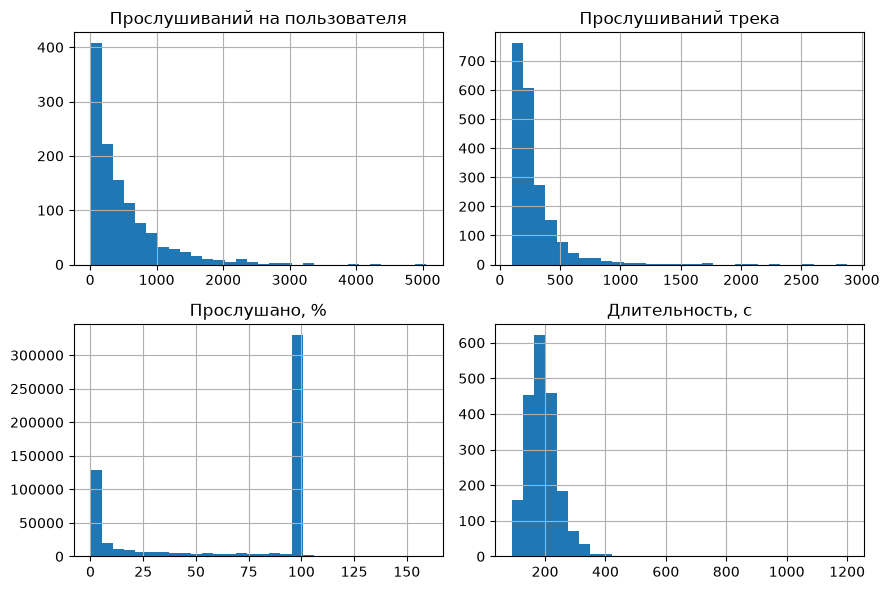

In [7]:
listens = events[events.event_type == "listen"]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
values = [listens.groupby("user").size(), listens.groupby("item").size(), listens.played_ratio_pct, metadata.duration]
titles = ["Прослушиваний на пользователя", "Прослушиваний трека", "Прослушано, %", "Длительность, с"]

for ax, data, title in zip(axes.flat, values, titles):
    data.hist(ax=ax, bins=30)
    ax.set_title(title)

plt.tight_layout()

Для FM добавляем исполнителя, альбом и длительность: они связывают треки по содержанию и формату. Используем только признаки, известные до рекомендации.

## Оценка
Делим по времени на train/validation/test. Релевантен новый трек, прослушанный больше чем наполовину.

Кандидаты — весь обучающий каталог без знакомых треков. Холодные пользователи, новые объекты и пользователи без релевантных треков исключены. Протокол общий для всех моделей.

Основная метрика — **NDCG@10**: учитывает порядок. **Recall@10** показывает долю найденных треков. Усредняем по пользователям; параметры выбираем на validation.

In [8]:
def binary_matrix(frame):
    pairs = frame[["user", "item"]].drop_duplicates()
    return csr_matrix((np.ones(len(pairs)), (pairs.user, pairs.item)), shape=shape)


def split(start, end):
    past = history[history.timestamp < start]
    listens = past[(past.event_type == "listen") & (past.timestamp >= START)].copy()
    listens["fraction"] = listens.played_ratio_pct.clip(0, 100) / 100
    pairs = listens.groupby(["user", "item"]).agg(count=("item_id", "size"), fraction=("fraction", "mean"))

    for name, undo in [("like", "unlike"), ("dislike", "undislike")]:
        actions = past[past.event_type.isin([name, undo])]
        latest = actions.drop_duplicates(["user", "item"], keep="last").set_index(["user", "item"])
        pairs[f"{name}d"] = (latest.event_type == name).reindex(pairs.index, fill_value=False)

    pairs = pairs.reset_index()
    counts = csr_matrix((pairs["count"], (pairs.user, pairs.item)), shape=shape, dtype=np.float32)
    seen = binary_matrix(past)

    future = history[(history.timestamp >= start) & (history.timestamp < end)]
    positive = future[(future.event_type == "listen") & (future.played_ratio_pct > 50)]
    truth = binary_matrix(positive)
    truth -= truth.multiply(seen)
    truth.eliminate_zeros()
    users = np.flatnonzero(truth.getnnz(axis=1))

    return counts, pairs, seen, truth, users


counts, pairs, seen, val_truth, val_users = split(VALIDATION, TEST)
print("Train: пар", counts.nnz, "; validation: пользователей", len(val_users))

Train: пар 155628 ; validation: пользователей 812


## Модели
$X$ — бинарная матрица прослушиваний, $n$ — их количество.

**ItemKNN:** косинусная близость и $k$ соседей:
$$s(i,j)=\frac{X_{:i}^TX_{:j}}{\|X_{:i}\|\|X_{:j}\|},\quad \hat r_{ui}=\sum_{j\in N_k(i)}X_{uj}s(j,i).$$

**iALS:** по очереди обучаем векторы пользователей и треков:
$$\min_{A,B}\sum_{ui}c_{ui}(X_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2),\quad c=1+\alpha\log(1+n).$$
Оценка — $a_u^Tb_i$.

**EASE:** линейно восстанавливаем взаимодействия по другим трекам:
$$P=(X^TX+\lambda I)^{-1},\quad W_{ij}=-P_{ij}/P_{jj},\quad W_{ii}=0,\quad \hat R=XW.$$

**FM:** учитываем попарные сочетания признаков:
$$f(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$
Обучаем BCE с L2; на прослушанную пару берём один случайный неизвестный трек.

**Кастомный iALS:** заменяем бинарный таргет на
$$q_{ui}=clip\left(0.5\bar r_{ui}+0.25\min\left(\frac{\log(1+n_{ui})}{\log6},1\right)+0.25L_{ui}-0.5D_{ui},0,1\right).$$
$\bar r$ — средняя доля дослушивания, ограниченная единицей; $L,D$ — лайк и дизлайк с учётом отмен. Идея: дослушивание, повторы и лайки означают интерес, дизлайк его снижает. Confidence не меняем.

Перебираемые параметры — ниже, остальные фиксированы в классах моделей. Seed=42.

In [9]:
spaces = {
    "ItemKNN": [{"k": 25}, {"k": 100}],
    "iALS": [{"reg": 1}, {"reg": 10}],
    "EASE": [{"reg": 100}, {"reg": 500}],
    "FM": [{"lr": 0.01}, {"lr": 0.03}],
    "Custom iALS": [{"reg": 1}, {"reg": 10}],
}

classes = {"ItemKNN": ItemKNN, "iALS": IALS, "EASE": EASE, "FM": FM, "Custom iALS": CustomIALS}


def fit_model(name, params, counts, pairs, seen, features):
    model = classes[name](**params)

    if name == "FM":
        return model.fit(counts, features, seen)
    if name == "Custom iALS":
        return model.fit(counts, pairs)
    return model.fit(counts)

In [10]:
rows = []

for name, configs in spaces.items():
    for params in configs:
        model = fit_model(name, params, counts, pairs, seen, features)
        rows.append({"model": name, "params": params, **evaluate(model, val_truth, val_users, seen)})

validation = pd.DataFrame(rows)
best = {}
for name in spaces:
    trials = validation[validation.model == name]
    best[name] = trials.loc[trials["NDCG@10"].idxmax(), "params"]

validation.round(5)

,model,params,Recall@10,NDCG@10
0,ItemKNN,{'k': 25},0.08699,0.09490
1,ItemKNN,{'k': 100},0.09369,0.09894
2,iALS,{'reg': 1},0.07837,0.09163
3,iALS,{'reg': 10},0.08269,0.09589
4,EASE,{'reg': 100},0.09566,0.10651
5,EASE,{'reg': 500},0.09490,0.11024
6,FM,{'lr': 0.01},0.06351,0.07744
7,FM,{'lr': 0.03},0.05535,0.06902
8,Custom iALS,{'reg': 1},0.08270,0.09261
9,Custom iALS,{'reg': 10},0.08327,0.09707


## Результаты
Обучаем на train+validation, проверяем на test. Отдельно убираем метаданные FM и меняем таргет iALS при одинаковых настройках.

In [11]:
counts, pairs, seen, test_truth, test_users = split(TEST, END)

assert test_truth.multiply(seen).nnz == 0
print("Test: пользователей", len(test_users), "; релевантных пар", test_truth.nnz)

rows = []

for name, params in best.items():
    model = fit_model(name, params, counts, pairs, seen, features)
    rows.append({"model": name, "params": params, **evaluate(model, test_truth, test_users, seen)})

results = pd.DataFrame(rows).set_index("model")
results.sort_values("NDCG@10", ascending=False).round(5)

Test: пользователей 822 ; релевантных пар 8363


,params,Recall@10,NDCG@10
model,,,
EASE,{'reg': 500},0.10250,0.10370
ItemKNN,{'k': 100},0.08855,0.09473
iALS,{'reg': 10},0.08504,0.09159
Custom iALS,{'reg': 10},0.07558,0.08316
FM,{'lr': 0.01},0.07060,0.07887


In [12]:
fm = fit_model("FM", best["FM"], counts, pairs, seen, features[:, :1])
custom = fit_model("Custom iALS", best["iALS"], counts, pairs, seen, features)

controls = pd.DataFrame({
    "FM без метаданных": evaluate(fm, test_truth, test_users, seen),
    "Custom iALS с параметрами iALS": evaluate(custom, test_truth, test_users, seen),
}).T

controls.round(5)

,Recall@10,NDCG@10
FM без метаданных,0.07183,0.08457
Custom iALS с параметрами iALS,0.07558,0.08316


## Выводы
EASE с `reg=500` лучший по обеим метрикам. Метаданные FM и кастомный таргет iALS здесь ухудшили качество.

Вывод ограничен популярным каталогом, одним seed и небольшим поиском; значимость различий не проверялась. Пропуск взаимодействия не означает неприязни.

Test уже просматривался до уменьшения выборки под лимит объёма; формулу таргета и настройки поиска не меняли.